# Piloto LLM: Sentimiento Financiero sobre Anexos SEC Form 8-K (`8k-exhibits-2010-2023.parquet`)

Este notebook diseña, evalúa y optimiza la clasificación de sentimiento financiero con LLMs para los **anexos materiales (*Exhibits*) de los reportes regulatorios Form 8-K** de los 6 grandes bancos sistémicos de EE. UU. (`JPM`, `BAC`, `WFC`, `C`, `GS`, `MS`), almacenados en Cloudflare R2 bajo `raw/sec/8k-exhibits-2010-2023.parquet`.

### Diferencias estructurales frente a prensa financiera y decisiones de arquitectura
1. **Emisor único y trazabilidad relacional (`Banco <-> Ítem 8-K <-> Exhibit`):** A diferencia de la prensa generalista, cada anexo 8-K pertenece inequívocamente a un único banco emisor (`ticker`), eliminando la ambigüedad *multi-ticker*. Cruzando por `accession_number` contra `raw/sec/8k-2010-2023.parquet`, vinculamos cada anexo con su **Ítem 8-K padre** (`Item 2.02` resultados, `Item 8.01` eventos materiales, `Item 5.02` gobierno/ejecutivos, `Item 7.01` presentaciones FD, `Item 1.01` fusiones/contratos).
2. **Contrato de salida unificado (`base_sentiment.py`):** Los LLMs devuelven exactamente las mismas variables que el motor de sentimiento de artículos (`label` en `{-1, 0, 1}`, `sentiment_score` continuo en `[-1.0, 1.0]`, `p_pos`, `p_neg`, `p_neu` y `motivo`), permitiendo integrar ambas fuentes en la capa *Gold* sin fricción y maximizando **Accuracy** y **Recall direccional (`+1` / `-1`)**.
3. **Optimización radical de costes en 3 etapas:**
   - **Etapa 1 — Embudo estructural determinista (`$0`):** Filtra anexos legales/técnicos de emisiones de deuda (`EX-1`, `EX-3`, `EX-4`, `EX-5`, `EX-8`, `EX-12`, `EX-23`, `EX-24`, `EX-25`, etc.) y deduplica anexos secundarios (`EX-99.2+` cuando ya existe `EX-99.1`/`EX-99` en el mismo `accession_number`), podando **>82% del corpus a coste `$0`**.
   - **Etapa 2 — Compresión rápida de doble corte (`comprimir_anexo_sec`):** Los anexos `EX-99.1`, `EX-10.1` y `EX-2.1` alcanzan hasta 65.000 palabras y tienen el texto HTML aplanado en una sola línea. Reciclamos `SENTENCE_SPLIT_REGEX`, `SAFE_HARBOR_PATTERN` y `SUBSTANTIVE_METRICS_PATTERN` sobre una ventana $O(1)$ en RAM para eliminar tablas numéricas, índices contractuales (*Table of Contents*) y avisos legales, entregando al LLM **~1.200 caracteres (~280 tokens/anexo, >94% de ahorro)**.
   - **Etapa 3 — Inferencia por lotes (`batch_size=10`) + Caché incremental:** Reutilizamos `BaseSentimentEngine` y `AnthropicSentimentEngine` sin dependencias externas adicionales, amortizando el *System Prompt* entre 10 anexos por llamada.

### Hoja de ruta experimental (`N = 100` anexos auditados)
* **Bloque 1:** Carga desde Cloudflare R2 (`cargar_parquet_local_o_r2`), cruce relacional `Banco <-> Ítem 8-K <-> Exhibit` y cuantificación del embudo `$0`.
* **Bloque 2:** Compresión `comprimir_anexo_sec` y alineación con el Ground Truth específico de anexos (`ground_truth_sec_exhibits.csv`, `N = 100`).
* **Experimento 1:** Benchmark multi-proveedor (`.env`: Gemini, OpenAI, Anthropic, xAI) + desglose de métricas por **Ítem 8-K** y por **Banco**.
* **Experimento 2:** *Prompt Engineering* regulatorio (`sec_v1_en` vs `sec_v2_rules`).
* **Experimento 3:** Ablación de ventana de contexto (`800` vs `1.200` vs `2.000` caracteres) y `batch_size` (`5` vs `10` vs `15`).
* **Experimento 4:** Calculadora de producción sobre el universo completo de anexos sustantivos, frontera de Pareto Coste vs Macro-F1 y matriz de confusión.

## 1. Configuración, Credenciales (`.env`), Infraestructura Reutilizada y Catálogo de Modelos

In [11]:
import asyncio
import importlib
import json
import os
import re
import sys
import time
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

curr = Path.cwd()
PROJ_ROOT = next((p for p in [curr, *curr.parents] if (p / "pyproject.toml").exists()), curr)
for p in (PROJ_ROOT / "src", PROJ_ROOT):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

import config.settings as _settings_mod
importlib.reload(_settings_mod)

from articulos.models.base_nlp import SENTENCE_SPLIT_REGEX
from articulos.models.sentiment.base_sentiment import (
    BaseSentimentEngine,
    EntradaSentimiento,
    clean_secret,
)
from articulos.models.sentiment.sentiment_llm import AnthropicSentimentEngine
from config.settings import settings
from sec.clasificador_estructural import SAFE_HARBOR_PATTERN, SUBSTANTIVE_METRICS_PATTERN
from shared.ids import generar_input_hash
from shared.parquet_cache import cargar_parquet_local_o_r2
from shared.tickets import TICKETS

plt.style.use("seaborn-v0_8-whitegrid")

GEMINI_API_KEY = clean_secret(settings.gemini_api_key or os.getenv("GEMINI_API_KEY", ""))
OPENAI_API_KEY = clean_secret(settings.openai_api_key or os.getenv("OPENAI_API_KEY", ""))
ANTHROPIC_API_KEY = clean_secret(settings.anthropic_api_key or os.getenv("ANTHROPIC_API_KEY", ""))
XAI_API_KEY = clean_secret(settings.xai_api_key or os.getenv("XAI_API_KEY", ""))

PROVEEDORES_ACTIVOS = {
    "gemini": bool(GEMINI_API_KEY),
    "openai": bool(OPENAI_API_KEY),
    "anthropic": bool(ANTHROPIC_API_KEY),
    "xai": bool(XAI_API_KEY),
}

# Catálogo de límites gratuitos, precios estándar (USD por 1M tokens) y parámetros de inferencia
CATALOGO_MODELOS: dict[str, dict[str, Any]] = {
    "gemini-2.5-flash":             {"prov": "gemini",    "rpm": 5,   "tpm": 250_000, "rpd": 20,  "in_usd_1m": 0.30, "out_usd_1m": 2.50,  "pause_s": 13.0, "send_temp": True},
    "gemini-3.1-flash-lite":        {"prov": "gemini",    "rpm": 15,  "tpm": 250_000, "rpd": 500, "in_usd_1m": 0.25, "out_usd_1m": 1.50,  "pause_s": 4.5,  "send_temp": True},
    "gemini-3.5-flash-lite":        {"prov": "gemini",    "rpm": 15,  "tpm": 250_000, "rpd": 500, "in_usd_1m": 0.30, "out_usd_1m": 2.50,  "pause_s": 4.5,  "send_temp": True},
    "gpt-5-nano":                   {"prov": "openai",    "rpm": 500, "tpm": 200_000, "rpd": 0,   "in_usd_1m": 0.05, "out_usd_1m": 0.40,  "pause_s": 0.4,  "send_temp": False},
    "gpt-4o-mini":                  {"prov": "openai",    "rpm": 500, "tpm": 200_000, "rpd": 0,   "in_usd_1m": 0.15, "out_usd_1m": 0.60,  "pause_s": 0.4,  "send_temp": True},
    "gpt-5-mini":                   {"prov": "openai",    "rpm": 500, "tpm": 200_000, "rpd": 0,   "in_usd_1m": 0.25, "out_usd_1m": 2.00,  "pause_s": 0.4,  "send_temp": False},
    "gpt-4.1-mini":                 {"prov": "openai",    "rpm": 500, "tpm": 200_000, "rpd": 0,   "in_usd_1m": 0.40, "out_usd_1m": 1.60,  "pause_s": 0.4,  "send_temp": True},
    "claude-haiku-5-5":             {"prov": "anthropic", "rpm": 50,  "tpm": 50_000,  "rpd": 0,   "in_usd_1m": 0.10, "out_usd_1m": 0.50,  "pause_s": 1.2,  "send_temp": False},
    "claude-haiku-4-5-20251001":    {"prov": "anthropic", "rpm": 50,  "tpm": 50_000,  "rpd": 0,   "in_usd_1m": 1.00, "out_usd_1m": 5.00,  "pause_s": 1.2,  "send_temp": True},
    "claude-sonnet-4-6":            {"prov": "anthropic", "rpm": 50,  "tpm": 30_000,  "rpd": 0,   "in_usd_1m": 3.00, "out_usd_1m": 15.00, "pause_s": 1.5,  "send_temp": False},
    "grok-4.20-0309-non-reasoning": {"prov": "xai",       "rpm": 60,  "tpm": 250_000, "rpd": 0,   "in_usd_1m": 1.25, "out_usd_1m": 2.50,  "pause_s": 0.8,  "send_temp": True},
    "grok-4.3":                     {"prov": "xai",       "rpm": 60,  "tpm": 250_000, "rpd": 0,   "in_usd_1m": 1.25, "out_usd_1m": 2.50,  "pause_s": 0.8,  "send_temp": True},
}

print(f"[OK] PROJ_ROOT: {PROJ_ROOT}")
print(
    "[OK] APIs activas en .env -> "
    + " | ".join(f"{k}: {'SÍ' if v else 'NO'}" for k, v in PROVEEDORES_ACTIVOS.items())
)

[OK] PROJ_ROOT: c:\Users\felip\OneDrive\Felipe\Master\TFM\TFM-Master
[OK] APIs activas en .env -> gemini: SÍ | openai: SÍ | anthropic: SÍ | xai: SÍ


## 2. Bloque 1 — Carga desde Cloudflare R2, Cruce Relacional (`Banco <-> Ítem 8-K <-> Exhibit`) y Embudo `$0`

Los anexos de `raw/sec/8k-exhibits-2010-2023.parquet` se vinculan en el archivo maestro bajo `Item 9.01` (*Financial Statements and Exhibits*). Para saber **a qué banco y a qué evento material (`Item 2.02`, `Item 8.01`, `Item 5.02`, `Item 7.01`, `Item 1.01`, etc.) corresponde cada anexo**, realizamos un *join* relacional exacto por `accession_number` contra `raw/sec/8k-2010-2023.parquet`.

A continuación aplicamos el **embudo determinista de coste `$0`** antes de invocar cualquier LLM:
1. **`deterministic_neutral_legal_debt` (`label = 0`, `$0`):** Anexos puramente técnicos/jurídicos de emisiones de bonos y notas estructuradas (`EX-1`, `EX-3`, `EX-4`, `EX-5`, `EX-8`, `EX-12`, `EX-15`, `EX-16`, `EX-23`, `EX-24`, `EX-25`, `EX-31`, `EX-32`, `EX-95`). Cuidado crítico con prefijos: usamos regex con frontera exacta para **no** capturar `EX-10.*` ni `EX-2.*`.
2. **`dedup_secondary_ex99` (`$0`):** Cuando un mismo `accession_number` incluye `EX-99.1`/`EX-99` (nota de prensa principal) y además `EX-99.2` o `EX-99.3` (tablas suplementarias o portada redundante), evaluamos únicamente el anexo primario para no pagar dos veces por el mismo trimestre.
3. **`discard_empty_or_supplement` (`$0`):** Anexos vacíos, con error de descarga o suplementos contables huérfanos sin narrativa.
4. **`llm_target`:** Universo neto de anexos sustantivos únicos (`EX-99.1`/`EX-99`, `EX-10.*`, `EX-2.*`) que pasan a inferencia LLM.

 INFO     | 2026-11-24 18:58:02.699645 | ParquetCache | Reutilizando 8k-exhibits-2010-2023 local: [c:\Users\felip\OneDrive\Felipe\Master\TFM\TFM-Master\data\raw\sec\8k-exhibits-2010-2023.parquet]
 INFO     | 2026-11-24 18:58:03.595460 | ParquetCompactor | Descompactados 5,531 registros desde buffer Parquet (35,584,298 bytes).
 INFO     | 2026-11-24 18:58:04.307321 | ParquetCache | Reutilizando 8k-2010-2023 local: [c:\Users\felip\OneDrive\Felipe\Master\TFM\TFM-Master\data\raw\sec\8k-2010-2023.parquet]
 INFO     | 2026-11-24 18:58:04.524327 | ParquetCompactor | Descompactados 5,424 registros desde buffer Parquet (1,649,271 bytes).
[OK] Total anexos 8-K: 5,531 | Podados a coste $0: 4,557 (82.4%) | Candidatos sustantivos LLM: 974


,Etapa del Embudo,Anexos,% Corpus,Coste API
0,deterministic_neutral_legal_debt,4047,73.17,$0.00 (Determinista)
1,llm_target,974,17.61,Inferencia LLM
2,dedup_secondary_ex99,497,8.99,$0.00 (Determinista)
3,discard_empty_or_error,13,0.24,$0.00 (Determinista)



=== DISTRIBUCIÓN RELACIONAL DE CANDIDATOS LLM (BANCO × ÍTEM 8-K PADRE) ===


linked_item,8.01,9.01,Item 1.01,Item 2.01,Item 2.02,Item 2.05,Item 2.06,Item 3.03,Item 5.01,Item 5.02,Item 5.03,Item 5.04,Item 5.05,Item 7.01,Item 8.01,Item 9.01,All
ticker,,,,,,,,,,,,,,,,,
BAC,0,0,1,0,57,0,2,0,0,25,1,0,0,5,46,0,137
C,0,1,1,0,73,1,0,1,0,40,7,0,0,3,42,38,207
GS,0,0,0,0,50,0,0,0,0,17,0,0,0,4,23,1,95
JPM,1,0,0,0,57,0,0,2,0,19,0,0,0,94,93,0,266
MS,0,0,6,1,55,0,0,0,0,25,0,0,0,2,19,0,108
WFC,0,0,0,0,56,0,0,0,1,37,0,1,2,0,63,1,161
All,1,1,8,1,348,1,2,3,1,163,8,1,2,108,286,40,974


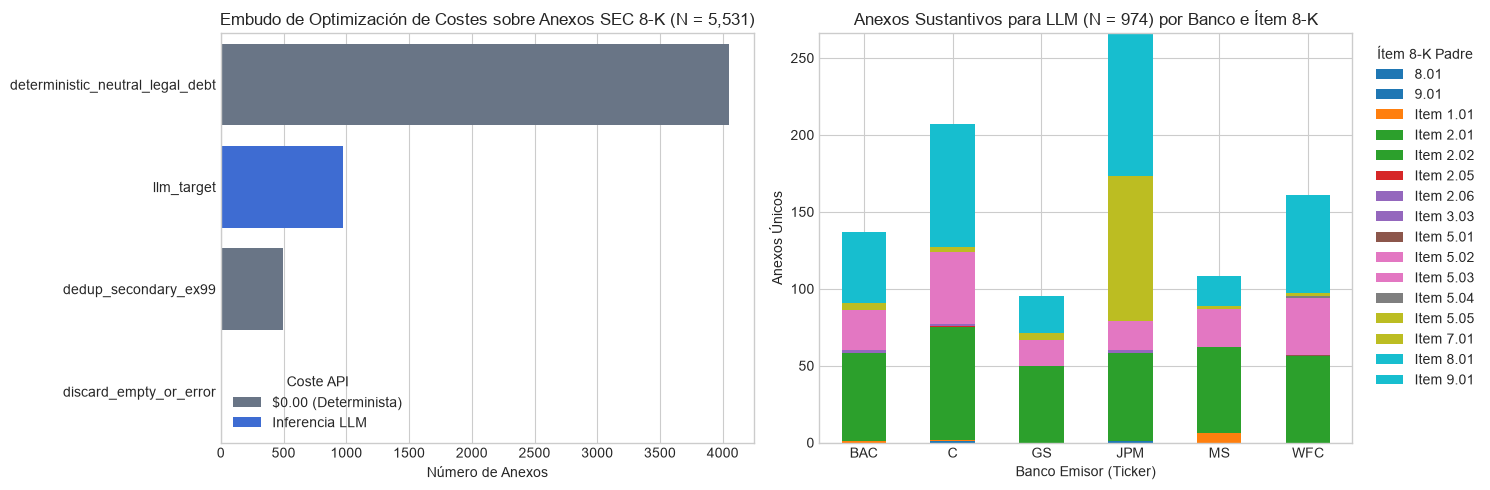

In [12]:
S3_KEY_EXHIBITS = "raw/sec/8k-exhibits-2010-2023.parquet"
S3_KEY_8K_ITEMS = "raw/sec/8k-2010-2023.parquet"

LOCAL_EXHIBITS = PROJ_ROOT / "data" / "raw" / "sec" / "8k-exhibits-2010-2023.parquet"
LOCAL_8K_ITEMS = PROJ_ROOT / "data" / "raw" / "sec" / "8k-2010-2023.parquet"

# Prioridad de ítems sustantivos del Form 8-K cuando un reporte declara múltiples secciones
PRIORIDAD_ITEMS_8K: tuple[str, ...] = (
    "Item 2.02",  # Results of Operations and Financial Condition (Earnings)
    "Item 1.01",  # Entry into a Material Definitive Agreement (M&A / Contracts)
    "Item 1.02",  # Termination of a Material Definitive Agreement
    "Item 2.01",  # Completion of Acquisition or Disposition of Assets
    "Item 2.05",  # Costs Associated with Exit or Disposal Activities
    "Item 2.06",  # Material Impairments
    "Item 4.02",  # Non-Reliance on Previously Issued Financial Statements
    "Item 8.01",  # Other Events (Buybacks, Dividends, Fines, Litigation, Redemptions)
    "Item 5.02",  # Departure/Election of Directors or Principal Officers; Comp Plans
    "Item 7.01",  # Regulation FD Disclosure (Investor / Earnings Slides)
)

REGEX_ANEXOS_DEUDA_LEGAL: re.Pattern[str] = re.compile(
    r"^EX-(?:1|3|4|5|8|12|15|16|23|24|25|31|32|95)(?:\.\d+|[A-Z]|\b|$)",
    re.IGNORECASE,
)


def vincular_items_8k(df_ex: pd.DataFrame, df_8k: pd.DataFrame) -> pd.DataFrame:
    """Vincula cada anexo 8-K con su banco emisor y su ítem sustantivo padre vía accession_number."""
    items_por_acc: dict[str, list[str]] = {}
    desc_por_acc_item: dict[tuple[str, str], str] = {}

    for row in df_8k[["accession_number", "item", "item_description"]].itertuples(index=False):
        acc = str(row.accession_number)
        it = str(row.item or "").strip()
        if it:
            items_por_acc.setdefault(acc, []).append(it)
            desc_por_acc_item.setdefault((acc, it), str(row.item_description or "")[:100])

    linked_items: list[str] = []
    linked_descs: list[str] = []
    resolved_all: list[str] = []

    rank_map = {it: idx for idx, it in enumerate(PRIORIDAD_ITEMS_8K)}

    for row in df_ex[["accession_number", "filing_items"]].itertuples(index=False):
        acc = str(row.accession_number)
        candidatos = sorted(set(items_por_acc.get(acc, [])))
        if not candidatos and row.filing_items:
            candidatos = [x.strip() for x in str(row.filing_items).split(",") if x.strip()]

        sustantivos = [it for it in candidatos if it != "Item 9.01"]
        if sustantivos:
            elegido = min(sustantivos, key=lambda x: rank_map.get(x, 999))
        elif candidatos:
            elegido = candidatos[0]
        else:
            elegido = "Item 8.01"

        linked_items.append(elegido)
        linked_descs.append(desc_por_acc_item.get((acc, elegido), ""))
        resolved_all.append(", ".join(candidatos) if candidatos else elegido)

    out = df_ex.copy()
    out["filing_date"] = out["filing_date"].astype(str).str.slice(0, 10)
    out["linked_item"] = linked_items
    out["linked_item_desc"] = linked_descs
    out["resolved_8k_items"] = resolved_all
    out["exhibit_family"] = out["exhibit_type"].astype(str).str.upper().str.extract(r"^(EX-\d+)", expand=False).fillna("OTHER")
    return out


def aplicar_embudo_estructural_sec(df_rel: pd.DataFrame) -> pd.DataFrame:
    """Clasifica los anexos en reglas deterministas de coste $0 frente a candidatos reales para LLM."""
    out = df_rel.copy()

    # Identificar qué accession_numbers ya cuentan con un anexo primario EX-99 / EX-99.1 / EX-99.01
    primarios_99 = {"EX-99", "EX-99.1", "EX-99.01"}
    acc_con_primario_99 = set(
        out.loc[out["exhibit_type"].astype(str).str.strip().str.upper().isin(primarios_99), "accession_number"]
    )

    rutas: list[str] = []
    for row in out[["accession_number", "exhibit_type", "exhibit_description", "content", "error"]].itertuples(index=False):
        ext = str(row.exhibit_type or "").strip().upper()
        desc = str(row.exhibit_description or "").strip().upper()
        txt = str(row.content or "")

        if row.error or len(txt.strip()) < 80:
            rutas.append("discard_empty_or_error")
        elif REGEX_ANEXOS_DEUDA_LEGAL.match(ext):
            rutas.append("deterministic_neutral_legal_debt")
        elif ext.startswith("EX-99") and ext not in primarios_99 and row.accession_number in acc_con_primario_99:
            rutas.append("dedup_secondary_ex99")
        elif ext in {"EX-99.2", "EX-99.3"} and ("SUPPLEMENT" in desc or " FINANCIAL SUPPLEMENT" in txt[:400].upper()):
            rutas.append("deterministic_neutral_supplement")
        else:
            rutas.append("llm_target")

    out["funnel_stage"] = rutas
    return out


rows_ex = await cargar_parquet_local_o_r2(LOCAL_EXHIBITS, S3_KEY_EXHIBITS, nombre="8k-exhibits-2010-2023")
rows_8k = await cargar_parquet_local_o_r2(LOCAL_8K_ITEMS, S3_KEY_8K_ITEMS, nombre="8k-2010-2023")
if not rows_ex or not rows_8k:
    raise RuntimeError("No se pudieron cargar los parquets SEC desde disco local ni desde Cloudflare R2.")

df_exhibits_raw = pd.DataFrame(rows_ex)
df_8k_raw = pd.DataFrame(rows_8k)

df_exhibits = aplicar_embudo_estructural_sec(vincular_items_8k(df_exhibits_raw, df_8k_raw))
df_llm_target = df_exhibits[df_exhibits["funnel_stage"] == "llm_target"].reset_index(drop=True)

resumen_embudo = (
    df_exhibits["funnel_stage"]
    .value_counts()
    .rename_axis("Etapa del Embudo")
    .reset_index(name="Anexos")
)
resumen_embudo["% Corpus"] = (resumen_embudo["Anexos"] / len(df_exhibits) * 100).round(2)
resumen_embudo["Coste API"] = resumen_embudo["Etapa del Embudo"].map(
    lambda x: "Inferencia LLM" if x == "llm_target" else "$0.00 (Determinista)"
)

print(
    f"[OK] Total anexos 8-K: {len(df_exhibits):,} | "
    f"Podados a coste $0: {len(df_exhibits) - len(df_llm_target):,} ({(1 - len(df_llm_target)/len(df_exhibits))*100:.1f}%) | "
    f"Candidatos sustantivos LLM: {len(df_llm_target):,}"
)
display(resumen_embudo)

print("\n=== DISTRIBUCIÓN RELACIONAL DE CANDIDATOS LLM (BANCO × ÍTEM 8-K PADRE) ===")
tabla_banco_item = pd.crosstab(df_llm_target["ticker"], df_llm_target["linked_item"], margins=True)
display(tabla_banco_item)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(
    data=resumen_embudo,
    y="Etapa del Embudo",
    x="Anexos",
    hue="Coste API",
    dodge=False,
    palette={"$0.00 (Determinista)": "#64748b", "Inferencia LLM": "#2563eb"},
    ax=axes[0],
)
axes[0].set_title("Embudo de Optimización de Costes sobre Anexos SEC 8-K (N = 5,531)")
axes[0].set_xlabel("Número de Anexos")
axes[0].set_ylabel("")

ct_plot = pd.crosstab(df_llm_target["ticker"], df_llm_target["linked_item"])
ct_plot.plot(kind="bar", stacked=True, ax=axes[1], colormap="tab10")
axes[1].set_title(f"Anexos Sustantivos para LLM (N = {len(df_llm_target)}) por Banco e Ítem 8-K")
axes[1].set_xlabel("Banco Emisor (Ticker)")
axes[1].set_ylabel("Anexos Únicos")
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(title="Ítem 8-K Padre", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 3. Bloque 2 — Compresor Rápido de Doble Corte (`comprimir_anexo_sec`) y Ground Truth (`N = 100`)

El ETL de ingesta (`ETLProcesRawData8K`) limpió etiquetas HTML y colapsó los saltos de línea en espacios simples (`clean_text`). Como consecuencia, un contrato de fusión `EX-2.1` o un informe de resultados `EX-99.1` puede ocupar entre **15.000 y 430.000 caracteres** en una sola cadena continua.

Diseñamos `comprimir_anexo_sec` bajo la Opción 1 (aislado en este piloto para validación empírica) reciclando las expresiones regulares ya probadas del repositorio:
1. **Corte $O(1)$ en memoria (`scan_window = 5000`):** Evita ejecutar regex sobre cientos de kilobytes de definiciones jurídicas. En contratos `EX-2` / `EX-10` con largos índices (*Table of Contents*), conserva el título inicial y salta directamente a la cláusula `WHEREAS` (objeto económico del acuerdo) si aparece en los primeros `10.000` caracteres.
2. **Segmentación con `SENTENCE_SPLIT_REGEX` (`base_nlp.py`) y limpieza de ruido SEC:**
   - Descarta tablas financieras aplanadas donde la densidad de dígitos supera el **40%** (`dígitos / (dígitos + letras) > 0.40`).
   - Descarta líneas de índice contractual (`Section 1.01 ... 24`).
   - Corta bloques legales de *Forward-Looking Statements* (`SAFE_HARBOR_PATTERN` de `clasificador_estructural.py`) y pies corporativos (*About [Bank]*, teléfonos de *Media/Investor Relations*, *Conference Call dial-in*).
3. **Selección guiada por densidad financiera (`SUBSTANTIVE_METRICS_PATTERN`):** Conserva la apertura del anexo (titular y primer párrafo ejecutivo) y prioriza las frases con magnitudes financieras, dividendos, recompras, multas o citas del CEO en su orden original hasta `max_chars = 1200`.

[OK] Muestra Ground Truth alineada: N = 100 anexos únicos | Clases GT: {-1: 27, 0: 34, 1: 39}
[OK] Longitud media bruta: 41,934 chars (5,476 palabras) -> Comprimida (1200): 1,092 chars (~273 tokens) | Ahorro global de caracteres: 97.4%


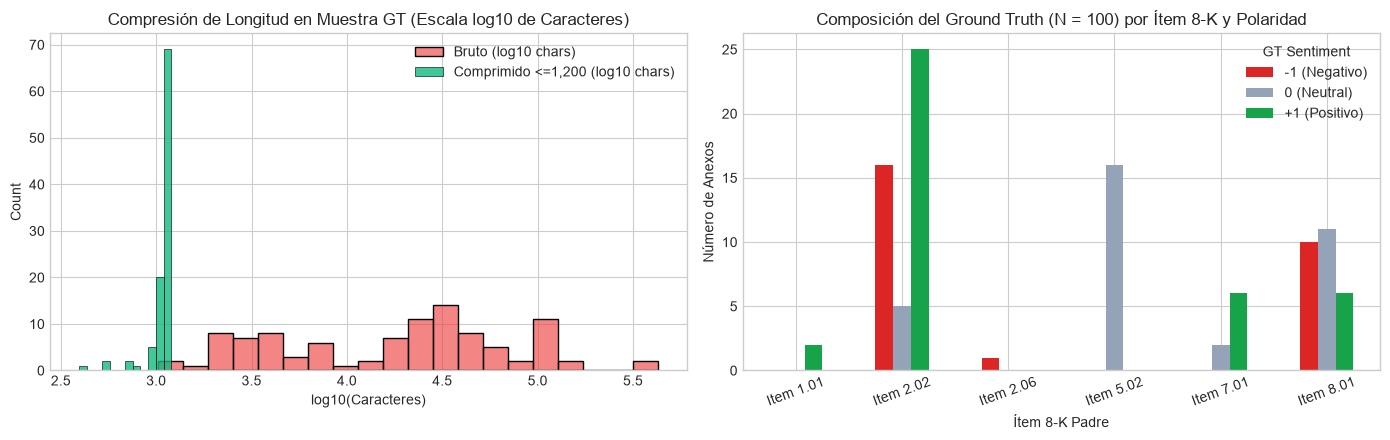


=== EJEMPLO DE TRAZABILIDAD Y COMPRESIÓN (EX-2.1 MERGER AGREEMENT) ===
Banco: MS (Morgan Stanley) | Fecha: 2020-02-21 | Ítem 8-K: Item 1.01 | Anexo: EX-2.1 | Bruto: 399,871 chars -> Comprimido: 723 chars
Extracto enviado al LLM: Exhibit 2.1EXECUTION VERSIONAGREEMENT AND PLAN OF MERGERdated as ofFebruary 20, 2020by and amongMorgan Stanley,MOON-EAGLE MERGER SUB, INC.andE*TRADE FINANCIAL CORPORATION. WHEREAS, the Board of Directors of the Company has unanimously (i) determined that this Agreement and the transactions contemplated hereby (including the Merger) are fair to and in the best interests of the Company’s stockholders, (ii) approved, adopted and declared advisable this Agreement and the transactions contemplated he ...


In [13]:
CSV_GT_SEC = PROJ_ROOT / "src" / "notebooks" / "sec" / "ground_truth_sec_exhibits.csv"

PR_BOILERPLATE_PATTERN: re.Pattern[str] = re.compile(
    r"(?:\bAbout\s+(?:JPMorgan|Bank of America|Wells Fargo|Citi|Citigroup|Goldman Sachs|Morgan Stanley)\b|"
    r"\b(?:Investor|Media)\s+(?:Relations|Contact|Contacts)\s*:|"
    r"\b(?:Reporters|Investors)\s+May\s+Contact\s*:|"
    r"\bconference\s+call\s+and\s+live\s+audio\s+webcast\b|"
    r"\bPursuant\s+to\s+the\s+requirements\s+of\s+the\s+Securities\s+Exchange\s+Act\b)",
    re.IGNORECASE,
)

TOC_LINE_PATTERN: re.Pattern[str] = re.compile(
    r"(?:TABLE\s+OF\s+CONTENTS|(?:Section|ARTICLE)\s+\d+(?:\.\d+)?[^.]{3,80}\s+\d{1,3}\s+(?:Section|ARTICLE)\s+\d+)",
    re.IGNORECASE,
)


def comprimir_anexo_sec(
    content: str,
    exhibit_type: str = "EX-99.1",
    max_chars: int = 1200,
    scan_window: int = 5000,
) -> str:
    """Comprime un anexo SEC 8-K extrayendo el núcleo ejecutivo sin tablas ni avisos legales.

    Args:
        content: Texto limpio completo del anexo en `8k-exhibits-2010-2023.parquet`.
        exhibit_type: Código del anexo (ej. `EX-99.1`, `EX-10.1`, `EX-2.1`).
        max_chars: Presupuesto máximo de caracteres enviado al LLM (~280 tokens para 1200 chars).
        scan_window: Ventana inicial máxima en caracteres escaneada en RAM.

    Returns:
        Extracto limpio y cronológico acotado a `max_chars`.
    """
    if not content:
        return ""

    ext_upper = str(exhibit_type or "").upper()
    # En contratos EX-2 / EX-10 con índice largo, conservar cabecera limpia + saltar a cláusulas WHEREAS
    if ext_upper.startswith(("EX-2", "EX-10")):
        pos_whereas = content[:10_000].upper().find("WHEREAS")
        if pos_whereas > 450:
            cabecera = re.split(r"TABLE\s+OF\s+CONTENTS", content[:500], maxsplit=1, flags=re.IGNORECASE)[0].strip()
            ventana = (cabecera[:350] + ". " if cabecera else "") + content[pos_whereas : pos_whereas + scan_window]
        else:
            ventana = content[:scan_window]
    else:
        ventana = content[:scan_window]

    # Truncar si aparece el bloque final de Safe Harbor / Forward-Looking Statements
    m_sh = SAFE_HARBOR_PATTERN.search(ventana)
    if m_sh and m_sh.start() > 250:
        ventana = ventana[: m_sh.start()]

    frases_brutas = SENTENCE_SPLIT_REGEX.split(ventana)
    frases_limpias: list[str] = []

    for f in frases_brutas:
        s = re.sub(r"\s+", " ", f).strip()
        if len(s) < 25:
            continue
        if SAFE_HARBOR_PATTERN.search(s) or PR_BOILERPLATE_PATTERN.search(s) or TOC_LINE_PATTERN.search(s):
            continue

        letras = sum(c.isalpha() for c in s)
        digitos = sum(c.isdigit() for c in s)
        if (letras + digitos) > 0 and (digitos / (letras + digitos)) > 0.40:
            continue

        # Si una "frase" aplanada es demasiado larga por falta de puntuación tras limpiar HTML, acotarla
        if len(s) > 550:
            s = s[:550].rsplit(" ", 1)[0] + "..."
        frases_limpias.append(s)

    if not frases_limpias:
        return re.sub(r"\s+", " ", content[:max_chars]).strip()

    # Seleccionar siempre las 2 primeras frases (titular + lead) y priorizar métricas sustantivas
    seleccion_idx: set[int] = set()
    presupuesto = 0

    for idx in range(min(2, len(frases_limpias))):
        largo = len(frases_limpias[idx]) + 1
        if presupuesto + largo <= max_chars or idx == 0:
            seleccion_idx.add(idx)
            presupuesto += largo

    for idx in range(2, len(frases_limpias)):
        if idx in seleccion_idx:
            continue
        frase = frases_limpias[idx]
        if SUBSTANTIVE_METRICS_PATTERN.search(frase):
            if presupuesto + len(frase) + 1 <= max_chars:
                seleccion_idx.add(idx)
                presupuesto += len(frase) + 1

    # Rellenar el presupuesto restante con contexto narrativo consecutivo
    for idx in range(2, len(frases_limpias)):
        if idx in seleccion_idx:
            continue
        frase = frases_limpias[idx]
        if presupuesto + len(frase) + 1 <= max_chars:
            seleccion_idx.add(idx)
            presupuesto += len(frase) + 1
        elif presupuesto >= int(max_chars * 0.85):
            break

    resultado = " ".join(frases_limpias[i] for i in sorted(seleccion_idx))
    return resultado[:max_chars].strip()


df_gt = pd.read_csv(CSV_GT_SEC)
lookup_ex = df_exhibits.drop_duplicates(subset=["accession_number", "exhibit_type"]).set_index(
    ["accession_number", "exhibit_type"]
)

filas_alineadas: list[dict[str, Any]] = []
for row in df_gt.itertuples(index=False):
    clave = (row.accession_number, row.exhibit_type)
    if clave not in lookup_ex.index:
        raise KeyError(f"Anexo GT no encontrado en parquet R2: {clave}")
    rec = lookup_ex.loc[clave].to_dict()
    rec["gt_id"] = int(row.id)
    rec["accession_number"] = row.accession_number
    rec["exhibit_type"] = row.exhibit_type
    rec["gt_sentiment"] = int(row.gt_sentiment)
    rec["gt_rationale"] = str(row.gt_rationale)
    filas_alineadas.append(rec)

df_eval = pd.DataFrame(filas_alineadas).reset_index(drop=True)
y_true = df_eval["gt_sentiment"].astype(int).to_numpy()

df_eval["raw_chars"] = df_eval["content"].astype(str).str.len()
df_eval["raw_words"] = df_eval["content"].astype(str).map(lambda s: len(s.split()))
df_eval["ctx_800"] = [comprimir_anexo_sec(c, e, max_chars=800) for c, e in zip(df_eval["content"], df_eval["exhibit_type"])]
df_eval["ctx_1200"] = [comprimir_anexo_sec(c, e, max_chars=1200) for c, e in zip(df_eval["content"], df_eval["exhibit_type"])]
df_eval["ctx_2000"] = [comprimir_anexo_sec(c, e, max_chars=2000) for c, e in zip(df_eval["content"], df_eval["exhibit_type"])]
df_eval["comp_chars_1200"] = df_eval["ctx_1200"].str.len()

ahorro_pct = (1.0 - df_eval["comp_chars_1200"].sum() / df_eval["raw_chars"].sum()) * 100.0
print(
    f"[OK] Muestra Ground Truth alineada: N = {len(df_eval)} anexos únicos | "
    f"Clases GT: {pd.Series(y_true).value_counts().sort_index().to_dict()}"
)
print(
    f"[OK] Longitud media bruta: {df_eval['raw_chars'].mean():,.0f} chars ({df_eval['raw_words'].mean():,.0f} palabras) -> "
    f"Comprimida (1200): {df_eval['comp_chars_1200'].mean():,.0f} chars (~{df_eval['comp_chars_1200'].mean()/4:.0f} tokens) | "
    f"Ahorro global de caracteres: {ahorro_pct:.1f}%"
)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(np.log10(df_eval["raw_chars"].clip(lower=1)), bins=20, color="#ef4444", alpha=0.65, label="Bruto (log10 chars)", ax=axes[0])
sns.histplot(np.log10(df_eval["comp_chars_1200"].clip(lower=1)), bins=12, color="#10b981", alpha=0.80, label="Comprimido <=1,200 (log10 chars)", ax=axes[0])
axes[0].set_title("Compresión de Longitud en Muestra GT (Escala log10 de Caracteres)")
axes[0].set_xlabel("log10(Caracteres)")
axes[0].legend()

gt_item_sent = pd.crosstab(df_eval["linked_item"], df_eval["gt_sentiment"])
gt_item_sent.plot(kind="bar", color=["#dc2626", "#94a3b8", "#16a34a"], ax=axes[1])
axes[1].set_title("Composición del Ground Truth (N = 100) por Ítem 8-K y Polaridad")
axes[1].set_xlabel("Ítem 8-K Padre")
axes[1].set_ylabel("Número de Anexos")
axes[1].tick_params(axis="x", rotation=20)
axes[1].legend(["-1 (Negativo)", "0 (Neutral)", "+1 (Positivo)"], title="GT Sentiment")
plt.tight_layout()
plt.show()

print("\n=== EJEMPLO DE TRAZABILIDAD Y COMPRESIÓN (EX-2.1 MERGER AGREEMENT) ===")
ej_ex2 = df_eval[df_eval["exhibit_family"] == "EX-2"].iloc[0]
print(
    f"Banco: {ej_ex2['ticker']} ({ej_ex2['company_name']}) | Fecha: {ej_ex2['filing_date']} | "
    f"Ítem 8-K: {ej_ex2['linked_item']} | Anexo: {ej_ex2['exhibit_type']} | "
    f"Bruto: {ej_ex2['raw_chars']:,} chars -> Comprimido: {ej_ex2['comp_chars_1200']} chars"
)
print("Extracto enviado al LLM:", ej_ex2["ctx_1200"][:500], "...")

## 4. Bloque 3 — Motor Multi-Proveedor sobre `BaseSentimentEngine`, Prompts SEC y Caché Incremental

Reutilizamos directamente la jerarquía de `src/articulos/models/sentiment/base_sentiment.py` y `sentiment_llm.py`:
* **Contrato idéntico a prensa/FinBERT:** `label` (`-1`, `0`, `1`), `sentiment_score` (`[-1.0, 1.0]`), `p_pos`, `p_neg`, `p_neu`, `motivo`.
* **Metadatos relacionales inyectados en cada elemento del lote:** `[idx=...] BANK: ... | 8-K ITEM: ... | EXHIBIT: ... | DATE: ... | EXCERPT: ...`.
* **Dos variantes de *System Prompt* en inglés** (menor consumo de tokens de entrada y mayor precisión en terminología contable SEC GAAP):
  - **`sec_v1_en`:** Prompt directo centrado en impacto fundamental para el accionista ordinario del banco emisor.
  - **`sec_v2_rules`:** Añade reglas explícitas de materialidad SEC para desambiguar `Item 5.02` (planes de acciones y relevos ordinarios -> `0`), `Item 8.01` (amortizaciones de deuda/preferentes a la par y *tender offers* rutinarias -> `0` frente a subidas de dividendo/recompras CCAR -> `+1` y multas DOJ/CFPB/OCC -> `-1`) e `Item 2.02` (prioridad de variaciones interanuales GAAP y cargos legales extraordinarios sobre retórica promocional del CEO).

In [14]:
CACHE_SEC_PILOT = PROJ_ROOT / "scratch" / "llm_sec_exhibits_pilot_cache.csv"

SEC_PROMPT_V1_EN = (
    "You are a senior quantitative equity analyst specializing in the 6 U.S. G-SIB banks "
    "(JPMorgan Chase, Bank of America, Wells Fargo, Citigroup, Goldman Sachs, Morgan Stanley).\n"
    "For each SEC Form 8-K Exhibit in the batch, evaluate the fundamental and equity-valuation impact "
    "for the common shareholders of the issuing BANK:\n"
    "- 1 (Positive): YoY earnings/EPS or revenue growth, record profitability, CCAR stress-test approval "
    "with dividend increases or share buyback authorizations, or accretive strategic acquisitions (EX-2.1).\n"
    "- -1 (Negative): Quarterly net losses, significant YoY net income/EPS contraction, regulatory consent orders "
    "or civil money penalties (DOJ, CFPB, OCC, SEC, Fed), costly litigation/RMBS settlements, goodwill impairments, "
    "dividend cuts, credit-rating/CRA downgrades, or sudden CEO health/enforcement crises.\n"
    "- 0 (Neutral): Routine debt/preferred stock issuances, par redemptions, or cash tender offer pricing; "
    "standard executive employment letters, planned retirements, board elections, or amended employee stock "
    "incentive plans (EX-10.1); segment reclassifications; technical warrant adjustments; or mixed earnings/presentations "
    "where positive and negative drivers offset each other without clear directional surprise.\n\n"
    "Return exactly one item in 'resultados' per 'idx' in the batch, preserving the exact integer 'idx'."
)

SEC_PROMPT_V2_RULES = SEC_PROMPT_V1_EN + (
    "\n\nSTRICT SEC MATERIALITY & ITEM DISAMBIGUATION RULES:\n"
    "1) Item 5.02 & EX-10.* (Governance / Compensation): Amended & restated equity incentive plans, PSU/RSU award "
    "templates, standard offer letters for incoming officers, and planned executive retirements without dispute -> ALWAYS 0.\n"
    "2) Item 8.01 Liability Management vs Capital Return: Calling/redeeming notes or preferred shares at par and "
    "pricing debt tender offers are routine treasury operations -> ALWAYS 0. Conversely, common dividend hikes and "
    "new common stock buyback authorizations -> ALWAYS 1; DOJ/CFPB/OCC fines, consent orders, foreclosure halts, "
    "or divestiture losses -> ALWAYS -1.\n"
    "3) Item 2.02 & Item 7.01 (Earnings Releases & Slides): Anchor on GAAP Net Income / Diluted EPS YoY trajectory "
    "and material one-off charges (multi-billion litigation or credit reserve builds). Do NOT let upbeat CEO quotes "
    "override a steep YoY earnings drop (-1), and classify genuinely offsetting mixed quarters as 0."
)

SEC_PROMPTS: dict[str, str] = {
    "sec_v1_en": SEC_PROMPT_V1_EN,
    "sec_v2_rules": SEC_PROMPT_V2_RULES,
}


class _SecPromptMixin:
    """Sobrescribe el formateo de usuario de BaseSentimentEngine para inyectar metadatos SEC 8-K."""

    def _build_user_prompt(self, lote: list[EntradaSentimiento]) -> str:
        bloques: list[str] = []
        for idx, item in enumerate(lote):
            ticker_info = TICKETS.get(item.ticker, {})
            banco = ticker_info.get("short_name") or ticker_info.get("name", item.ticker)
            bloques.append(
                f"[idx={idx}] BANK: {banco} ({item.ticker}) | {item.title} | EXCERPT: {item.contexto}"
            )
        return "Evaluate the following SEC Form 8-K exhibits:\n\n" + "\n\n".join(bloques)


class SecAnthropicEngine(_SecPromptMixin, AnthropicSentimentEngine):
    """Motor SEC sobre Anthropic Messages API reutilizando AnthropicSentimentEngine."""


class SecOpenAICompatEngine(_SecPromptMixin, BaseSentimentEngine):
    """Motor SEC compatible con OpenAI Chat Completions API y xAI Grok API."""

    def __init__(
        self,
        api_key: str,
        base_url: str,
        allowed_host: str,
        model: str,
        prompt_version: str,
        system_prompt: str,
        send_temp: bool = True,
        max_tokens: int = 8192,
    ) -> None:
        super().__init__(
            model=model,
            prompt_version=prompt_version,
            system_prompt=system_prompt,
            max_tokens=max_tokens,
            allowed_hosts=(allowed_host,),
        )
        self.api_key = clean_secret(api_key)
        self.base_url = base_url
        self.send_temp = send_temp

    def clasificar_lote_unico(self, lote: list[EntradaSentimiento]) -> dict[str, dict[str, Any]]:
        if not self.api_key:
            raise ValueError(f"API key vacía para {self.model}")
        payload: dict[str, Any] = {
            "model": self.model,
            "response_format": {"type": "json_object"},
            "messages": [
                {"role": "system", "content": self.system_prompt},
                {"role": "user", "content": self._build_user_prompt(lote)},
            ],
        }
        if self.send_temp:
            payload["temperature"] = 0.0
        if self.model.startswith("gpt-5"):
            payload["reasoning_effort"] = "low"
            payload["max_completion_tokens"] = self.max_tokens
        else:
            payload["max_tokens"] = self.max_tokens

        raw_resp = self._http_call(
            self.base_url,
            headers={"Content-Type": "application/json", "Authorization": f"Bearer {self.api_key}"},
            method="POST",
            payload=payload,
        )
        data = json.loads(raw_resp)
        usage = data.get("usage", {})
        content = data["choices"][0]["message"]["content"]
        return self._parsear_lote_texto(
            raw_text=content,
            lote_hashes=[e.input_hash for e in lote],
            input_tokens=int(usage.get("prompt_tokens", 0)),
            output_tokens=int(usage.get("completion_tokens", 0)),
        )

    def clasificar_realtime(self, entradas: list[EntradaSentimiento], batch_size: int = 10, max_retries: int = 3) -> dict[str, dict[str, Any]]:
        salida: dict[str, dict[str, Any]] = {}
        for start in range(0, len(entradas), batch_size):
            salida.update(self.clasificar_lote_unico(entradas[start : start + batch_size]))
        return salida


_GEMINI_RESPONSE_SCHEMA: dict[str, Any] = {
    "type": "OBJECT",
    "properties": {
        "resultados": {
            "type": "ARRAY",
            "items": {
                "type": "OBJECT",
                "properties": {
                    "idx": {"type": "INTEGER"},
                    "label": {"type": "INTEGER"},
                    "sentiment_score": {"type": "NUMBER"},
                    "p_pos": {"type": "NUMBER"},
                    "p_neg": {"type": "NUMBER"},
                    "p_neu": {"type": "NUMBER"},
                    "motivo": {"type": "STRING"},
                },
                "required": ["idx", "label", "sentiment_score", "p_pos", "p_neg", "p_neu", "motivo"],
            },
        }
    },
    "required": ["resultados"],
}


class SecGeminiEngine(_SecPromptMixin, BaseSentimentEngine):
    """Motor SEC sobre Google Gemini REST API con thinking desactivado/mínimo y esquema JSON estricto."""

    def __init__(self, api_key: str, model: str, prompt_version: str, system_prompt: str, max_tokens: int = 8192) -> None:
        super().__init__(
            model=model,
            prompt_version=prompt_version,
            system_prompt=system_prompt,
            max_tokens=max_tokens,
            allowed_hosts=("generativelanguage.googleapis.com",),
        )
        self.api_key = clean_secret(api_key)

    def _default_thinking_cfg(self) -> dict[str, Any] | None:
        m = self.model.lower()
        if m.startswith("gemini-2.5"):
            return {"thinkingBudget": 0}
        if m.startswith("gemini-3."):
            return {"thinkingLevel": "minimal"}
        if m.startswith("gemini-4"):
            return {"thinkingLevel": "low"}
        return None

    def clasificar_lote_unico(self, lote: list[EntradaSentimiento]) -> dict[str, dict[str, Any]]:
        if not self.api_key:
            raise ValueError("GEMINI_API_KEY no configurada.")
        url = f"https://generativelanguage.googleapis.com/v1beta/models/{self.model}:generateContent"
        gen_cfg: dict[str, Any] = {
            "maxOutputTokens": self.max_tokens,
            "responseMimeType": "application/json",
            "responseSchema": _GEMINI_RESPONSE_SCHEMA,
        }
        if not self.model.lower().startswith(("gemini-3.5", "gemini-4")):
            gen_cfg["temperature"] = 0.0
        think_cfg = self._default_thinking_cfg()
        if think_cfg is not None:
            gen_cfg["thinkingConfig"] = think_cfg

        payload: dict[str, Any] = {
            "systemInstruction": {"parts": [{"text": self.system_prompt}]},
            "contents": [{"role": "user", "parts": [{"text": self._build_user_prompt(lote)}]}],
            "generationConfig": gen_cfg,
        }
        headers = {"Content-Type": "application/json", "x-goog-api-key": self.api_key}
        try:
            raw_resp = self._http_call(url, headers=headers, method="POST", payload=payload)
        except RuntimeError as exc:
            # Fallback automático si una subversión REST rechaza thinkingLevel y exige thinkingBudget (o viceversa)
            err_l = str(exc).lower()
            if "http 400" in err_l and "thinking" in err_l:
                if gen_cfg.get("thinkingConfig") == {"thinkingLevel": "minimal"}:
                    gen_cfg["thinkingConfig"] = {"thinkingBudget": 0}
                else:
                    gen_cfg.pop("thinkingConfig", None)
                raw_resp = self._http_call(url, headers=headers, method="POST", payload=payload)
            else:
                raise

        data = json.loads(raw_resp)
        cands = data.get("candidates", [])
        if not cands:
            raise RuntimeError(f"Respuesta Gemini sin candidates: {str(data)[:250]}")
        parts = cands[0].get("content", {}).get("parts", [])
        txt = "\n".join(
            p["text"] for p in parts if isinstance(p, dict) and "text" in p and not p.get("thought", False)
        )
        usage = data.get("usageMetadata", {})
        in_tok = int(usage.get("promptTokenCount", 0) or 0)
        out_tok = int(usage.get("candidatesTokenCount", 0) or 0) + int(usage.get("thoughtsTokenCount", 0) or 0)
        return self._parsear_lote_texto(
            raw_text=txt,
            lote_hashes=[e.input_hash for e in lote],
            input_tokens=in_tok,
            output_tokens=out_tok,
        )

    def clasificar_realtime(self, entradas: list[EntradaSentimiento], batch_size: int = 10, max_retries: int = 3) -> dict[str, dict[str, Any]]:
        salida: dict[str, dict[str, Any]] = {}
        for start in range(0, len(entradas), batch_size):
            salida.update(self.clasificar_lote_unico(entradas[start : start + batch_size]))
        return salida


def construir_motor_sec(model_name: str, prompt_key: str) -> BaseSentimentEngine:
    """Instancia el adaptador de sentimiento correspondiente según el catálogo de proveedores."""
    meta = CATALOGO_MODELOS[model_name]
    prov = meta["prov"]
    sys_prompt = SEC_PROMPTS[prompt_key]
    if prov == "anthropic":
        return SecAnthropicEngine(
            api_key=ANTHROPIC_API_KEY,
            model=model_name,
            prompt_version=prompt_key,
            system_prompt=sys_prompt,
            max_tokens=4096,
        )
    if prov == "openai":
        return SecOpenAICompatEngine(
            api_key=OPENAI_API_KEY,
            base_url="https://api.openai.com/v1/chat/completions",
            allowed_host="api.openai.com",
            model=model_name,
            prompt_version=prompt_key,
            system_prompt=sys_prompt,
            send_temp=bool(meta.get("send_temp", True)),
        )
    if prov == "xai":
        return SecOpenAICompatEngine(
            api_key=XAI_API_KEY,
            base_url="https://api.x.ai/v1/chat/completions",
            allowed_host="api.x.ai",
            model=model_name,
            prompt_version=prompt_key,
            system_prompt=sys_prompt,
            send_temp=bool(meta.get("send_temp", True)),
        )
    if prov == "gemini":
        return SecGeminiEngine(
            api_key=GEMINI_API_KEY,
            model=model_name,
            prompt_version=prompt_key,
            system_prompt=sys_prompt,
        )
    raise ValueError(f"Proveedor no soportado: {prov}")


_COLUMNAS_CACHE = [
    "exp_id", "model", "accession_number", "exhibit_type", "ticker", "linked_item",
    "label", "sentiment_score", "p_pos", "p_neg", "p_neu", "motivo",
    "in_tokens", "out_tokens", "lat_ms",
]

_FATAL_TOKENS = (
    "HTTP 400", "HTTP 401", "HTTP 402", "HTTP 403", "HTTP 404",
    "credit_balance", "insufficient_quota", "model_not_found", "invalid_api_key", "API key vacía",
)


def _es_sobrecarga(msg: str) -> bool:
    m = msg.lower()
    return any(t in m for t in ("http 503", "http 429", "high demand", "overloaded", "rate limit"))


def _cargar_cache_sec() -> pd.DataFrame:
    if CACHE_SEC_PILOT.exists():
        return pd.read_csv(CACHE_SEC_PILOT)
    return pd.DataFrame(columns=_COLUMNAS_CACHE)


async def ejecutar_experimento_sec(
    df_in: pd.DataFrame,
    col_contexto: str,
    model_name: str,
    prompt_key: str = "sec_v1_en",
    batch_size: int = 10,
    pause_s: float | None = None,
) -> pd.DataFrame:
    """Ejecuta o recupera de caché un experimento LLM sobre anexos SEC con trazabilidad completa."""
    exp_id = f"{model_name}|{prompt_key}|{col_contexto}|b{batch_size}"
    df_cache = _cargar_cache_sec()
    prev = df_cache[(df_cache["exp_id"] == exp_id) & (~df_cache["motivo"].astype(str).isin(["error", "sin_respuesta"]))]
    cache_map: dict[tuple[str, str], dict[str, Any]] = {
        (str(r["accession_number"]), str(r["exhibit_type"])): r.to_dict() for _, r in prev.iterrows()
    }

    pendientes: list[tuple[Any, EntradaSentimiento]] = []
    for row in df_in.itertuples(index=False):
        clave = (str(row.accession_number), str(row.exhibit_type))
        if clave in cache_map:
            continue
        ctx_txt = str(getattr(row, col_contexto))
        meta_header = (
            f"8-K ITEM: {row.linked_item} | EXHIBIT: {row.exhibit_type} | "
            f"DATE: {row.filing_date} | DESC: {str(row.exhibit_description or '')[:70]}"
        )
        inp = EntradaSentimiento(
            input_hash=generar_input_hash(
                str(row.ticker),
                model_name,
                prompt_key,
                f"{row.accession_number}:{row.exhibit_type}|{ctx_txt}",
            ),
            ticker=str(row.ticker),
            title=meta_header,
            contexto=ctx_txt,
        )
        pendientes.append((row, inp))

    n_calls = (len(pendientes) + batch_size - 1) // batch_size
    print(f"[{exp_id}] En caché: {len(df_in) - len(pendientes)} | Pendientes: {len(pendientes)} ({n_calls} llamadas)", flush=True)

    if pendientes:
        meta = CATALOGO_MODELOS[model_name]
        prov = meta["prov"]
        if not PROVEEDORES_ACTIVOS.get(prov, False):
            print(f"  [SKIP] Proveedor '{prov}' sin API key activa en .env.", flush=True)
        else:
            motor = construir_motor_sec(model_name, prompt_key)
            wait_between = meta["pause_s"] if pause_s is None else pause_s
            abortar = False

            for start in range(0, len(pendientes), batch_size):
                if abortar:
                    break
                chunk = pendientes[start : start + batch_size]
                lote_entradas = [inp for _, inp in chunk]
                t0 = time.perf_counter()
                exito = False

                for intento in range(3):
                    try:
                        if isinstance(motor, SecAnthropicEngine):
                            res_lote = await asyncio.to_thread(motor.clasificar_realtime, lote_entradas, len(lote_entradas), 1)
                        else:
                            res_lote = await asyncio.to_thread(motor.clasificar_lote_unico, lote_entradas)

                        lat_doc = round((time.perf_counter() - t0) * 1000.0 / max(len(chunk), 1), 1)
                        for row_orig, inp in chunk:
                            parsed_it = res_lote.get(inp.input_hash)
                            if parsed_it is not None:
                                clave = (str(row_orig.accession_number), str(row_orig.exhibit_type))
                                cache_map[clave] = {
                                    "exp_id": exp_id,
                                    "model": model_name,
                                    "accession_number": str(row_orig.accession_number),
                                    "exhibit_type": str(row_orig.exhibit_type),
                                    "ticker": str(row_orig.ticker),
                                    "linked_item": str(row_orig.linked_item),
                                    "label": int(parsed_it["sentiment_label"]),
                                    "sentiment_score": float(parsed_it["sentiment_score"]),
                                    "p_pos": float(parsed_it["p_pos"]),
                                    "p_neg": float(parsed_it["p_neg"]),
                                    "p_neu": float(parsed_it["p_neu"]),
                                    "motivo": str(parsed_it["sentiment_motivo"]),
                                    "in_tokens": float(parsed_it["in_tokens"]),
                                    "out_tokens": float(parsed_it["out_tokens"]),
                                    "lat_ms": lat_doc,
                                }
                        exito = True
                        ejemplo_it = next(iter(res_lote.values()), {"in_tokens": 0.0, "out_tokens": 0.0})
                        print(
                            f"  Lote {start // batch_size + 1}/{n_calls} OK ({len(res_lote)}/{len(chunk)}) | "
                            f"{ejemplo_it['in_tokens']:.0f}+{ejemplo_it['out_tokens']:.0f} tok/anexo | {lat_doc:.0f} ms/anexo",
                            flush=True,
                        )
                        break
                    except Exception as exc:
                        msg = str(exc)
                        if any(ft in msg for ft in _FATAL_TOKENS):
                            print(f"  [ABORT] {model_name} error no recuperable: {msg[:220]}", flush=True)
                            abortar = True
                            break
                        espera = 4 * (2**intento) if _es_sobrecarga(msg) else (2**intento) * 6
                        print(f"  [WARN] Lote {start // batch_size + 1} intento {intento + 1}: {msg[:160]} -> reintento en {espera}s", flush=True)
                        if intento == 2:
                            break
                        await asyncio.sleep(espera)

                if not exito and not abortar:
                    print(f"  [CIRCUIT BREAKER] {model_name} agotó reintentos (sobrecarga/cuota). Se salta al siguiente modelo; relanza la celda más tarde para completar los pendientes (el resto está en caché).", flush=True)
                    abortar = True

                if exito:
                    CACHE_SEC_PILOT.parent.mkdir(parents=True, exist_ok=True)
                    df_otros = _cargar_cache_sec()
                    df_otros = df_otros[df_otros["exp_id"] != exp_id]
                    df_actual = pd.DataFrame(list(cache_map.values()), columns=_COLUMNAS_CACHE)
                    pd.concat([df_otros, df_actual], ignore_index=True).to_csv(CACHE_SEC_PILOT, index=False, encoding="utf-8")

                if not abortar and (start + batch_size < len(pendientes)):
                    await asyncio.sleep(wait_between)

    filas_out: list[dict[str, Any]] = []
    for row in df_in.itertuples(index=False):
        clave = (str(row.accession_number), str(row.exhibit_type))
        filas_out.append(
            cache_map.get(
                clave,
                {
                    "exp_id": exp_id,
                    "model": model_name,
                    "accession_number": str(row.accession_number),
                    "exhibit_type": str(row.exhibit_type),
                    "ticker": str(row.ticker),
                    "linked_item": str(row.linked_item),
                    "label": 0,
                    "sentiment_score": 0.0,
                    "p_pos": 0.0,
                    "p_neg": 0.0,
                    "p_neu": 1.0,
                    "motivo": "sin_respuesta",
                    "in_tokens": np.nan,
                    "out_tokens": np.nan,
                    "lat_ms": np.nan,
                },
            )
        )
    return pd.DataFrame(filas_out)


def calcular_kpis_sec(y_true_arr: np.ndarray, df_pred: pd.DataFrame, nombre: str) -> dict[str, Any]:
    """Calcula Accuracy, Macro-Precision, Macro-Recall, Macro-F1/F2, Recall por clase e inversiones."""
    valid_mask = ~df_pred["motivo"].astype(str).isin(["error", "sin_respuesta"])
    if int(valid_mask.sum()) == 0:
        return {
            "Experimento": nombre, "N": 0, "Accuracy": np.nan, "Precision": np.nan,
            "Recall": np.nan, "F1-Score": np.nan, "F2(β=2)": np.nan,
            "Rec+1": np.nan, "Rec0": np.nan, "Rec-1": np.nan, "Inv": 0,
            "InTok/doc": np.nan, "OutTok/doc": np.nan, "ms/doc": np.nan,
        }
    yt = y_true_arr[valid_mask]
    yp = df_pred.loc[valid_mask, "label"].astype(int).to_numpy()
    acc = float((yt == yp).mean())
    precs, recs, f1s, f2s = {}, {}, {}, {}
    for c in (-1, 0, 1):
        tp = int(((yt == c) & (yp == c)).sum())
        fp = int(((yt != c) & (yp == c)).sum())
        fn = int(((yt == c) & (yp != c)).sum())
        p = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        r = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        f1 = 2 * p * r / (p + r) if (p + r) > 0 else 0.0
        f2 = 5 * p * r / (4 * p + r) if (4 * p + r) > 0 else 0.0
        precs[c], recs[c], f1s[c], f2s[c] = p, r, f1, f2

    return {
        "Experimento": nombre,
        "N": int(valid_mask.sum()),
        "Accuracy": round(acc, 3),
        "Precision": round(float(np.mean(list(precs.values()))), 3),
        "Recall": round(float(np.mean(list(recs.values()))), 3),
        "F1-Score": round(float(np.mean(list(f1s.values()))), 3),
        "F2(β=2)": round(float(np.mean(list(f2s.values()))), 3),
        "Rec+1": round(recs[1], 3),
        "Rec0": round(recs[0], 3),
        "Rec-1": round(recs[-1], 3),
        "Inv": int((((yt == 1) & (yp == -1)) | ((yt == -1) & (yp == 1))).sum()),
        "InTok/doc": round(float(df_pred["in_tokens"].mean()), 1) if df_pred["in_tokens"].notna().any() else np.nan,
        "OutTok/doc": round(float(df_pred["out_tokens"].mean()), 1) if df_pred["out_tokens"].notna().any() else np.nan,
        "ms/doc": round(float(df_pred["lat_ms"].mean()), 1) if df_pred["lat_ms"].notna().any() else np.nan,
    }


def desglosar_metricas_relacionales(
    df_gt_aligned: pd.DataFrame,
    df_pred: pd.DataFrame,
    columna_grupo: str,
) -> pd.DataFrame:
    """Desglosa Accuracy, Recall y F1 por dimensión relacional (linked_item o ticker) sin groupby.apply."""
    filas: list[dict[str, Any]] = []
    valores = sorted(df_gt_aligned[columna_grupo].astype(str).unique())
    for val in valores:
        mask = (df_gt_aligned[columna_grupo].astype(str) == val).to_numpy()
        kpi = calcular_kpis_sec(
            df_gt_aligned.loc[mask, "gt_sentiment"].astype(int).to_numpy(),
            df_pred.loc[mask].reset_index(drop=True),
            val,
        )
        filas.append(
            {
                columna_grupo: val,
                "N": kpi["N"],
                "Accuracy": kpi["Accuracy"],
                "Recall": kpi["Recall"],
                "F1-Score": kpi["F1-Score"],
                "Rec+1": kpi["Rec+1"],
                "Rec0": kpi["Rec0"],
                "Rec-1": kpi["Rec-1"],
                "Inv": kpi["Inv"],
            }
        )
    return pd.DataFrame(filas).sort_values("N", ascending=False).reset_index(drop=True)

## 5. Experimento 1 — Benchmark Multi-Proveedor (`N = 100` Anexos SEC) y Trazabilidad por Ítem/Banco

Evaluamos los modelos calidad/precio de las APIs configuradas en `.env` bajo condiciones idénticas (`ctx_1200` + `sec_v1_en`, `batch_size = 10`, solo `10` llamadas HTTP por modelo). Además del ranking global por `F1-Score` y `Recall`, auditamos el rendimiento desglosado por **Ítem 8-K (`linked_item`)** y por **Banco (`ticker`)** sobre el mejor modelo.

In [15]:
MODELOS_EXP1 = [
    m for m, meta in CATALOGO_MODELOS.items() if PROVEEDORES_ACTIVOS.get(meta["prov"], False)
]

resultados_exp: dict[str, pd.DataFrame] = {}
kpis_exp1: list[dict[str, Any]] = []

for mod in MODELOS_EXP1:
    df_p = await ejecutar_experimento_sec(
        df_eval,
        col_contexto="ctx_1200",
        model_name=mod,
        prompt_key="sec_v1_en",
        batch_size=10,
    )
    resultados_exp[f"{mod}|sec_v1_en"] = df_p
    kpis_exp1.append(calcular_kpis_sec(y_true, df_p, mod))

df_leaderboard_exp1 = (
    pd.DataFrame(kpis_exp1)
    .sort_values(["F1-Score", "Recall", "Accuracy"], ascending=False)
    .reset_index(drop=True)
)
print("=== LEADERBOARD GLOBAL — EXPERIMENTO 1 (N = 100 ANEXOS SEC 8-K) ===")
display(df_leaderboard_exp1)

validos_exp1 = df_leaderboard_exp1[df_leaderboard_exp1["N"] > 0]
MODELO_GANADOR = str(validos_exp1.iloc[0]["Experimento"]) if not validos_exp1.empty else "claude-haiku-5-5"
print(f"\n[OK] Modelo líder seleccionado para análisis relacional y ablaciones: {MODELO_GANADOR}")

if f"{MODELO_GANADOR}|sec_v1_en" in resultados_exp and not validos_exp1.empty:
    df_best_pred = resultados_exp[f"{MODELO_GANADOR}|sec_v1_en"]
    print(f"\n=== RENDIMIENTO DE {MODELO_GANADOR} POR ÍTEM 8-K PADRE (linked_item) ===")
    display(desglosar_metricas_relacionales(df_eval, df_best_pred, "linked_item"))

    print(f"\n=== RENDIMIENTO DE {MODELO_GANADOR} POR BANCO EMISOR (ticker) ===")
    display(desglosar_metricas_relacionales(df_eval, df_best_pred, "ticker"))

[gemini-2.5-flash|sec_v1_en|ctx_1200|b10] En caché: 100 | Pendientes: 0 (0 llamadas)
[gemini-3.1-flash-lite|sec_v1_en|ctx_1200|b10] En caché: 0 | Pendientes: 100 (10 llamadas)
  [WARN] Lote 1 intento 1: HTTP 503: {
  "error": {
    "code": 503,
    "message": "This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try a -> reintento en 4s
  [WARN] Lote 1 intento 2: HTTP 503: {
  "error": {
    "code": 503,
    "message": "This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try a -> reintento en 8s
  [WARN] Lote 1 intento 3: HTTP 503: {
  "error": {
    "code": 503,
    "message": "This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try a -> reintento en 16s
  [CIRCUIT BREAKER] gemini-3.1-flash-lite agotó reintentos (sobrecarga/cuota). Se salta al siguiente modelo; relanza la celda más tarde para completar los pendientes (el resto está en caché).
[gemini-3.

,Experimento,N,Accuracy,Precision,Recall,F1-Score,F2(β=2),Rec+1,Rec0,Rec-1,Inv,InTok/doc,OutTok/doc,ms/doc
0,claude-haiku-5-5,100,0.92,0.927,0.923,0.925,0.924,0.923,0.882,0.963,0,620.8,164.3,649.8
1,grok-4.3,100,0.92,0.923,0.920,0.922,0.921,0.923,0.912,0.926,1,393.4,61.6,1067.9
2,claude-sonnet-4-6,100,0.92,0.920,0.923,0.921,0.922,0.923,0.882,0.963,1,434.4,93.8,1262.5
3,gpt-4o-mini,100,0.90,0.900,0.899,0.899,0.899,0.949,0.824,0.926,1,378.4,49.1,745.1
4,grok-4.20-0309-non-reasoning,100,0.88,0.889,0.875,0.880,0.876,0.949,0.824,0.852,1,392.6,61.1,439.9
5,claude-haiku-4-5-20251001,100,0.87,0.880,0.866,0.871,0.868,0.923,0.824,0.852,1,434.3,97.3,825.5
6,gpt-5-mini,100,0.87,0.881,0.861,0.867,0.863,0.923,0.882,0.778,2,378.3,92.2,1296.1
7,gemini-2.5-flash,100,0.86,0.865,0.861,0.863,0.862,0.872,0.824,0.889,0,411.6,70.7,701.4
8,gpt-4.1-mini,100,0.86,0.872,0.851,0.858,0.853,0.923,0.853,0.778,1,378.4,63.4,632.6
9,gpt-5-nano,100,0.82,0.849,0.799,0.809,0.800,0.974,0.794,0.630,6,378.3,151.4,962.3



[OK] Modelo líder seleccionado para análisis relacional y ablaciones: claude-haiku-5-5

=== RENDIMIENTO DE claude-haiku-5-5 POR ÍTEM 8-K PADRE (linked_item) ===


,linked_item,N,Accuracy,Recall,F1-Score,Rec+1,Rec0,Rec-1,Inv
0,Item 2.02,46,0.913,0.787,0.808,0.960,0.400,1.0,0
1,Item 8.01,27,0.926,0.936,0.927,1.000,0.909,0.9,0
2,Item 5.02,16,1.000,0.333,0.333,0.000,1.000,0.0,0
3,Item 7.01,8,0.750,0.556,0.489,0.667,1.000,0.0,0
4,Item 1.01,2,1.000,0.333,0.333,1.000,0.000,0.0,0
5,Item 2.06,1,1.000,0.333,0.333,0.000,0.000,1.0,0



=== RENDIMIENTO DE claude-haiku-5-5 POR BANCO EMISOR (ticker) ===


,ticker,N,Accuracy,Recall,F1-Score,Rec+1,Rec0,Rec-1,Inv
0,WFC,25,0.960,0.952,0.961,0.857,1.000,1.00,0
1,JPM,20,0.900,0.949,0.906,0.846,1.000,1.00,0
2,C,16,0.750,0.806,0.758,1.000,0.667,0.75,0
3,MS,15,0.933,0.917,0.935,1.000,0.750,1.00,0
4,BAC,13,1.000,1.000,1.000,1.000,1.000,1.00,0
5,GS,11,1.000,1.000,1.000,1.000,1.000,1.00,0


## 6. Experimento 2 — *Prompt Engineering* Regulatorio (`sec_v1_en` vs `sec_v2_rules`)

Comprobamos si añadir las reglas explícitas de desambiguación SEC (`sec_v2_rules`: planes de incentivos `EX-10.1`, amortizaciones de deuda a la par bajo `Item 8.01` y anclaje estricto en variaciones interanuales GAAP bajo `Item 2.02`) reduce los falsos positivos/negativos y mejora el `F1-Score` sobre los mejores modelos económicos de cada proveedor.

In [16]:
# Seleccionamos hasta 3 modelos representativos (el ganador + alternativas rápidas calidad/precio)
candidatos_exp2: list[str] = []
for m in [MODELO_GANADOR, "claude-haiku-5-5", "gpt-4.1-mini", "gemini-3.5-flash-lite"]:
    if m in MODELOS_EXP1 and m not in candidatos_exp2:
        candidatos_exp2.append(m)
candidatos_exp2 = candidatos_exp2[:3]

filas_exp2: list[dict[str, Any]] = []
for mod in candidatos_exp2:
    if f"{mod}|sec_v1_en" in resultados_exp:
        filas_exp2.append(calcular_kpis_sec(y_true, resultados_exp[f"{mod}|sec_v1_en"], f"{mod} (sec_v1_en)"))
    df_v2 = await ejecutar_experimento_sec(
        df_eval,
        col_contexto="ctx_1200",
        model_name=mod,
        prompt_key="sec_v2_rules",
        batch_size=10,
    )
    resultados_exp[f"{mod}|sec_v2_rules"] = df_v2
    filas_exp2.append(calcular_kpis_sec(y_true, df_v2, f"{mod} (sec_v2_rules)"))

df_exp2 = pd.DataFrame(filas_exp2)
print("=== COMPARATIVA PROMPT V1 vs PROMPT V2 REGLAS SEC (N = 100) ===")
display(df_exp2)

# Elegir mejor prompt para el modelo ganador en el Experimento 3
PROMPT_OPT = "sec_v1_en"
if f"{MODELO_GANADOR}|sec_v2_rules" in resultados_exp and f"{MODELO_GANADOR}|sec_v1_en" in resultados_exp:
    f1_v1 = calcular_kpis_sec(y_true, resultados_exp[f"{MODELO_GANADOR}|sec_v1_en"], "v1")["F1-Score"]
    f1_v2 = calcular_kpis_sec(y_true, resultados_exp[f"{MODELO_GANADOR}|sec_v2_rules"], "v2")["F1-Score"]
    if pd.notna(f1_v2) and (pd.isna(f1_v1) or f1_v2 >= f1_v1):
        PROMPT_OPT = "sec_v2_rules"
print(f"[OK] Configuración óptima seleccionada para ablación de contexto: {MODELO_GANADOR} + {PROMPT_OPT}")

[claude-haiku-5-5|sec_v2_rules|ctx_1200|b10] En caché: 0 | Pendientes: 100 (10 llamadas)
  Lote 1/10 OK (10/10) | 659+211 tok/anexo | 835 ms/anexo
  Lote 2/10 OK (10/10) | 703+170 tok/anexo | 641 ms/anexo
  Lote 3/10 OK (10/10) | 679+150 tok/anexo | 544 ms/anexo
  Lote 4/10 OK (10/10) | 650+168 tok/anexo | 632 ms/anexo
  Lote 5/10 OK (10/10) | 629+190 tok/anexo | 722 ms/anexo
  Lote 6/10 OK (10/10) | 686+148 tok/anexo | 560 ms/anexo
  Lote 7/10 OK (10/10) | 663+179 tok/anexo | 688 ms/anexo
  Lote 8/10 OK (10/10) | 616+153 tok/anexo | 582 ms/anexo
  Lote 9/10 OK (10/10) | 677+164 tok/anexo | 648 ms/anexo
  Lote 10/10 OK (10/10) | 656+248 tok/anexo | 981 ms/anexo
[gpt-4.1-mini|sec_v2_rules|ctx_1200|b10] En caché: 0 | Pendientes: 100 (10 llamadas)
  Lote 1/10 OK (10/10) | 391+65 tok/anexo | 829 ms/anexo
  Lote 2/10 OK (10/10) | 415+62 tok/anexo | 654 ms/anexo
  Lote 3/10 OK (10/10) | 415+63 tok/anexo | 736 ms/anexo
  Lote 4/10 OK (10/10) | 402+64 tok/anexo | 626 ms/anexo
  Lote 5/10 OK (1

,Experimento,N,Accuracy,Precision,Recall,F1-Score,F2(β=2),Rec+1,Rec0,Rec-1,Inv,InTok/doc,OutTok/doc,ms/doc
0,claude-haiku-5-5 (sec_v1_en),100,0.92,0.927,0.923,0.925,0.924,0.923,0.882,0.963,0,620.8,164.3,649.8
1,claude-haiku-5-5 (sec_v2_rules),100,0.94,0.939,0.944,0.941,0.942,0.949,0.882,1.000,0,661.9,178.0,683.2
2,gpt-4.1-mini (sec_v1_en),100,0.86,0.872,0.851,0.858,0.853,0.923,0.853,0.778,1,378.4,63.4,632.6
3,gpt-4.1-mini (sec_v2_rules),100,0.87,0.881,0.861,0.867,0.863,0.923,0.882,0.778,1,400.5,63.1,1428.5
4,gemini-3.5-flash-lite (sec_v1_en),0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN
5,gemini-3.5-flash-lite (sec_v2_rules),0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN


[OK] Configuración óptima seleccionada para ablación de contexto: claude-haiku-5-5 + sec_v2_rules


## 7. Experimento 3 — Ablación de Ventana de Contexto (`800` vs `1.200` vs `2.000` chars) y `batch_size`

Sobre una submuestra estratificada de `N = 60` anexos evaluamos dos palancas críticas de coste:
1. **Longitud del extracto comprimido (`ctx_800` vs `ctx_1200` vs `ctx_2000`):** Verificamos empíricamente si ampliar a `2.000` caracteres aporta *Recall* adicional o si, al igual que ocurrió en prensa (`1.000` vs `2.500` chars), introduce ruido secundario encareciendo la factura de entrada un ~60%.
2. **Tamaño de lote por llamada (`batch_size = 5` vs `10` vs `15`):** Medimos la amortización de tokens del *System Prompt* frente a la estabilidad de atención del LLM en lotes largos.

In [17]:
# Submuestra determinista estratificada N=60 manteniendo proporción exacta de clases (-1, 0, +1)
idx_sub60: list[int] = []
for clase, cupo in [(-1, 16), (0, 20), (1, 24)]:
    pos_clase = np.flatnonzero(y_true == clase)[:cupo].tolist()
    idx_sub60.extend(pos_clase)
idx_sub60 = sorted(idx_sub60)

df_sub60 = df_eval.iloc[idx_sub60].reset_index(drop=True)
y_sub60 = y_true[idx_sub60]

df_c800 = await ejecutar_experimento_sec(df_sub60, "ctx_800", MODELO_GANADOR, PROMPT_OPT, batch_size=10)
df_c1200_base = resultados_exp.get(f"{MODELO_GANADOR}|{PROMPT_OPT}")
if df_c1200_base is not None:
    df_c1200 = df_c1200_base.iloc[idx_sub60].reset_index(drop=True)
else:
    df_c1200 = await ejecutar_experimento_sec(df_sub60, "ctx_1200", MODELO_GANADOR, PROMPT_OPT, batch_size=10)
df_c2000 = await ejecutar_experimento_sec(df_sub60, "ctx_2000", MODELO_GANADOR, PROMPT_OPT, batch_size=10)

print(f"=== 3A. ABLACIÓN DE LONGITUD DE CONTEXTO ({MODELO_GANADOR} | N = 60) ===")
display(
    pd.DataFrame(
        [
            calcular_kpis_sec(y_sub60, df_c800, "ctx_800 (~200 tok)"),
            calcular_kpis_sec(y_sub60, df_c1200, "ctx_1200 (~280 tok) [Base]"),
            calcular_kpis_sec(y_sub60, df_c2000, "ctx_2000 (~450 tok)"),
        ]
    )
)

df_b5 = await ejecutar_experimento_sec(df_sub60, "ctx_1200", MODELO_GANADOR, PROMPT_OPT, batch_size=5)
df_b15 = await ejecutar_experimento_sec(df_sub60, "ctx_1200", MODELO_GANADOR, PROMPT_OPT, batch_size=15)

print(f"\n=== 3B. ABLACIÓN DE BATCH SIZE POR PETICIÓN ({MODELO_GANADOR} | N = 60) ===")
display(
    pd.DataFrame(
        [
            calcular_kpis_sec(y_sub60, df_b5, "batch_size = 5"),
            calcular_kpis_sec(y_sub60, df_c1200, "batch_size = 10 [Base]"),
            calcular_kpis_sec(y_sub60, df_b15, "batch_size = 15"),
        ]
    )
)

[claude-haiku-5-5|sec_v2_rules|ctx_800|b10] En caché: 0 | Pendientes: 60 (6 llamadas)
  Lote 1/6 OK (10/10) | 494+206 tok/anexo | 822 ms/anexo
  Lote 2/6 OK (10/10) | 551+217 tok/anexo | 830 ms/anexo
  Lote 3/6 OK (10/10) | 557+165 tok/anexo | 624 ms/anexo
  Lote 4/6 OK (10/10) | 518+160 tok/anexo | 596 ms/anexo
  Lote 5/6 OK (10/10) | 515+175 tok/anexo | 678 ms/anexo
  Lote 6/6 OK (10/10) | 511+139 tok/anexo | 522 ms/anexo
[claude-haiku-5-5|sec_v2_rules|ctx_2000|b10] En caché: 0 | Pendientes: 60 (6 llamadas)
  Lote 1/6 OK (10/10) | 872+173 tok/anexo | 684 ms/anexo
  Lote 2/6 OK (10/10) | 938+168 tok/anexo | 622 ms/anexo
  Lote 3/6 OK (10/10) | 955+147 tok/anexo | 561 ms/anexo
  Lote 4/6 OK (10/10) | 894+174 tok/anexo | 675 ms/anexo
  Lote 5/6 OK (10/10) | 836+183 tok/anexo | 719 ms/anexo
  Lote 6/6 OK (10/10) | 889+177 tok/anexo | 701 ms/anexo
=== 3A. ABLACIÓN DE LONGITUD DE CONTEXTO (claude-haiku-5-5 | N = 60) ===


,Experimento,N,Accuracy,Precision,Recall,F1-Score,F2(β=2),Rec+1,Rec0,Rec-1,Inv,InTok/doc,OutTok/doc,ms/doc
0,ctx_800 (~200 tok),60,0.867,0.865,0.868,0.866,0.867,0.917,0.75,0.938,0,524.1,176.9,678.5
1,ctx_1200 (~280 tok) [Base],60,0.900,0.898,0.906,0.900,0.903,0.917,0.80,1.000,0,667.5,173.3,657.6
2,ctx_2000 (~450 tok),60,0.883,0.884,0.889,0.883,0.886,0.917,0.75,1.000,0,897.3,170.4,660.6


[claude-haiku-5-5|sec_v2_rules|ctx_1200|b5] En caché: 0 | Pendientes: 60 (12 llamadas)
  Lote 1/12 OK (5/5) | 761+240 tok/anexo | 1040 ms/anexo
  Lote 2/12 OK (5/5) | 804+189 tok/anexo | 775 ms/anexo
  Lote 3/12 OK (5/5) | 817+148 tok/anexo | 621 ms/anexo
  Lote 4/12 OK (5/5) | 838+197 tok/anexo | 854 ms/anexo
  Lote 5/12 OK (5/5) | 795+170 tok/anexo | 690 ms/anexo
  Lote 6/12 OK (5/5) | 811+96 tok/anexo | 446 ms/anexo
  Lote 7/12 OK (5/5) | 795+163 tok/anexo | 674 ms/anexo
  Lote 8/12 OK (5/5) | 753+165 tok/anexo | 749 ms/anexo
  Lote 9/12 OK (5/5) | 777+228 tok/anexo | 999 ms/anexo
  Lote 10/12 OK (5/5) | 729+208 tok/anexo | 955 ms/anexo
  Lote 11/12 OK (5/5) | 813+165 tok/anexo | 682 ms/anexo
  Lote 12/12 OK (5/5) | 753+132 tok/anexo | 608 ms/anexo
[claude-haiku-5-5|sec_v2_rules|ctx_1200|b15] En caché: 0 | Pendientes: 60 (4 llamadas)
  Lote 1/4 OK (15/15) | 629+164 tok/anexo | 631 ms/anexo
  Lote 2/4 OK (15/15) | 650+149 tok/anexo | 541 ms/anexo
  Lote 3/4 OK (15/15) | 610+156 tok/a

,Experimento,N,Accuracy,Precision,Recall,F1-Score,F2(β=2),Rec+1,Rec0,Rec-1,Inv,InTok/doc,OutTok/doc,ms/doc
0,batch_size = 5,60,0.883,0.884,0.889,0.883,0.886,0.917,0.75,1.0,0,787.2,175.2,757.7
1,batch_size = 10 [Base],60,0.900,0.898,0.906,0.900,0.903,0.917,0.80,1.0,0,667.5,173.3,657.6
2,batch_size = 15,60,0.883,0.886,0.892,0.888,0.890,0.875,0.80,1.0,0,622.1,153.2,570.4


## 8. Experimento 4 — Calculadora de Producción (`5.531` Brutos -> `966` Sustantivos) y Diagnóstico Visual

Proyectamos el coste exacto y el tiempo de ejecución para procesar **todo el histórico 2010–2023 de anexos 8-K (`5.531` registros)**:
* **`4.565` anexos (`82.5%`)** resueltos instantáneamente a **`$0.00`** en la Etapa 1 (filtro estructural de deuda/legal + deduplicación `EX-99.2+`).
* **`966` anexos sustantivos únicos (`17.5%`)** procesados con los tokens reales de entrada/salida medidos en el piloto, comparando **API Estándar** frente a **Batch API (`-50%` de descuento en Anthropic/OpenAI)** y **Free Tier** en Gemini.

=== PROYECCIÓN DE PRODUCCIÓN HISTÓRICA COMPLETA: 5,531 ANEXOS -> 974 SUSTANTIVOS LLM (+4,557 RESUELTOS A $0.00) ===


,Modelo | Prompt,Proveedor,Accuracy (%),F1-Score,Recall,Rec+1,Rec0,Rec-1,Inv,In+Out tok,Llamadas (974 docs),Free Tier,Coste Std ($),Coste Batch -50% ($)
0,claude-haiku-5-5 (sec_v2_rules),Anthropic,94.0,0.941,0.944,0.949,0.882,1.000,0,662+178,98,Solo pago,0.151,0.076
1,claude-haiku-5-5 (sec_v1_en),Anthropic,92.0,0.925,0.923,0.923,0.882,0.963,0,621+164,98,Solo pago,0.140,0.070
2,grok-4.3 (sec_v1_en),Xai,92.0,0.922,0.920,0.923,0.912,0.926,1,393+62,98,Solo pago,0.629,0.314
3,claude-sonnet-4-6 (sec_v1_en),Anthropic,92.0,0.921,0.923,0.923,0.882,0.963,1,434+94,98,Solo pago,2.640,1.320
4,gpt-4o-mini (sec_v1_en),Openai,90.0,0.899,0.899,0.949,0.824,0.926,1,378+49,98,Solo pago,0.084,0.042
5,grok-4.20-0309-non-reasoning (sec_v1_en),Xai,88.0,0.880,0.875,0.949,0.824,0.852,1,393+61,98,Solo pago,0.627,0.313
6,claude-haiku-4-5-20251001 (sec_v1_en),Anthropic,87.0,0.871,0.866,0.923,0.824,0.852,1,434+97,98,Solo pago,0.897,0.448
7,gpt-4.1-mini (sec_v2_rules),Openai,87.0,0.867,0.861,0.923,0.882,0.778,1,400+63,98,Solo pago,0.254,0.127
8,gpt-5-mini (sec_v1_en),Openai,87.0,0.867,0.861,0.923,0.882,0.778,2,378+92,98,Solo pago,0.272,0.136
9,gemini-2.5-flash (sec_v1_en),Gemini,86.0,0.863,0.861,0.872,0.824,0.889,0,412+71,98,4.90 d,0.292,0.146


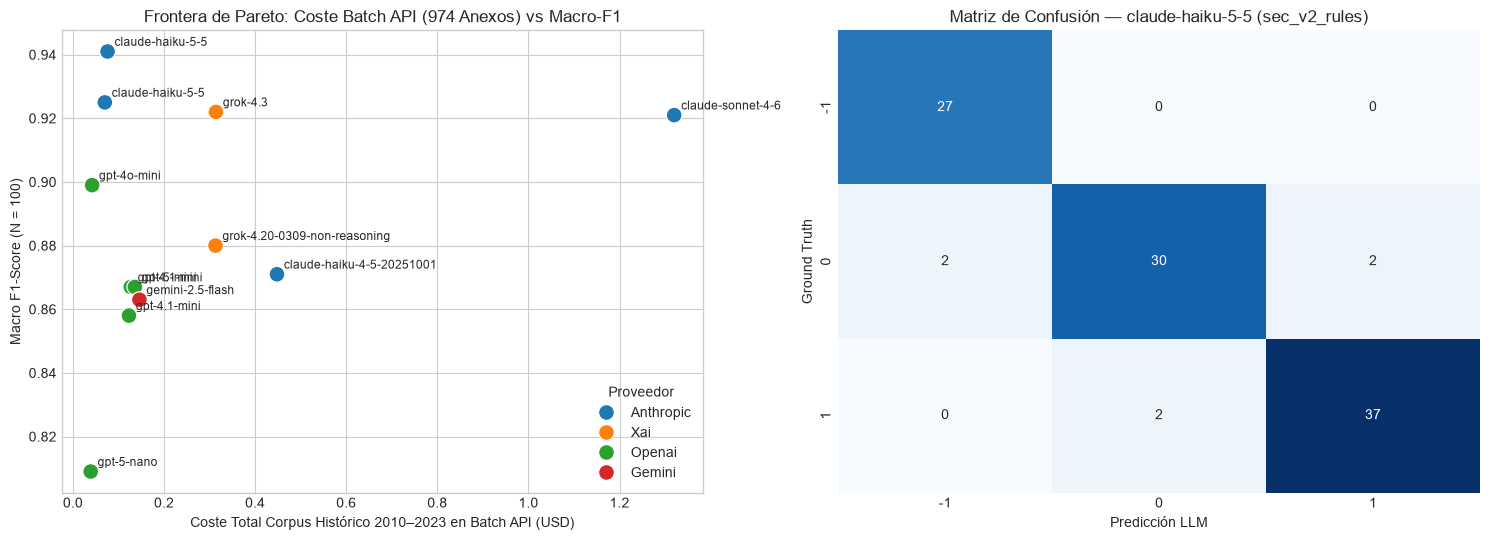


=== AUDITORÍA DE DISCREPANCIAS (6/100) — claude-haiku-5-5 (sec_v2_rules) ===


,ticker,filing_date,linked_item,exhibit_type,gt_sentiment,pred_label,pred_score,pred_motivo,gt_rationale
6,C,2010-10-18,Item 2.02,EX-99.1,0,1,0.40,Net income $2.2B versus $101M prior year despi...,Citigroup Q3 2010: métricas mixtas de capital ...
19,C,2013-01-17,Item 2.02,EX-99.1,0,1,0.45,Net income up YoY to $1.2B; EPS $0.38 vs $0.31,Citigroup Q4 2012: caída de pérdidas creditici...
37,WFC,2015-04-14,Item 2.02,EX-99.1,1,0,-0.05,"Net income and EPS roughly flat, revenue up 3%",Wells Fargo Q1 2015: aprobación sin objeciones...
44,WFC,2016-04-14,Item 2.02,EX-99.1,0,-1,-0.35,Q1 2016 net income and EPS declined YoY despit...,Wells Fargo Q1 2016: definición técnica de PTP...
46,WFC,2017-01-13,Item 2.02,EX-99.1,0,-1,-0.45,FY2016 net income and EPS fell YoY ($21.9B vs ...,Wells Fargo Q4 2016: descenso interanual en be...
48,JPM,2017-02-28,Item 7.01,EX-99,1,0,0.10,Investor day strategy slides; no new quantifie...,Presentación Investor Day 2017 de JPMorgan: be...


In [18]:
N_PROD_LLM = len(df_llm_target)
BATCH_PROD = 10
LLAMADAS_PROD = (N_PROD_LLM + BATCH_PROD - 1) // BATCH_PROD

filas_prod: list[dict[str, Any]] = []
for clave_exp, df_p in resultados_exp.items():
    mod_name, pr_key = clave_exp.split("|", 1)
    kpi = calcular_kpis_sec(y_true, df_p, clave_exp)
    if kpi["N"] == 0:
        continue
    meta = CATALOGO_MODELOS[mod_name]
    in_tok = kpi["InTok/doc"] if pd.notna(kpi["InTok/doc"]) else 310.0
    out_tok = kpi["OutTok/doc"] if pd.notna(kpi["OutTok/doc"]) else 95.0

    coste_std = (N_PROD_LLM * in_tok / 1_000_000.0) * meta["in_usd_1m"] + (
        N_PROD_LLM * out_tok / 1_000_000.0
    ) * meta["out_usd_1m"]
    coste_batch = coste_std * 0.50
    dias_free = f"{LLAMADAS_PROD / meta['rpd']:.2f} d" if meta["rpd"] > 0 else "Solo pago"

    filas_prod.append(
        {
            "Modelo | Prompt": f"{mod_name} ({pr_key})",
            "Proveedor": meta["prov"].capitalize(),
            "Accuracy (%)": round(kpi["Accuracy"] * 100, 1),
            "F1-Score": kpi["F1-Score"],
            "Recall": kpi["Recall"],
            "Rec+1": kpi["Rec+1"],
            "Rec0": kpi["Rec0"],
            "Rec-1": kpi["Rec-1"],
            "Inv": kpi["Inv"],
            "In+Out tok": f"{in_tok:.0f}+{out_tok:.0f}",
            f"Llamadas ({N_PROD_LLM} docs)": LLAMADAS_PROD,
            "Free Tier": dias_free,
            "Coste Std ($)": round(coste_std, 3),
            "Coste Batch -50% ($)": round(coste_batch, 3),
        }
    )

df_proyeccion_prod = pd.DataFrame(filas_prod).sort_values(["F1-Score", "Coste Batch -50% ($)"], ascending=[False, True]).reset_index(drop=True)
print(
    f"=== PROYECCIÓN DE PRODUCCIÓN HISTÓRICA COMPLETA: 5,531 ANEXOS -> {N_PROD_LLM} SUSTANTIVOS LLM "
    f"(+{len(df_exhibits) - N_PROD_LLM:,} RESUELTOS A $0.00) ==="
)
display(df_proyeccion_prod)

if not df_proyeccion_prod.empty:
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

    sns.scatterplot(
        data=df_proyeccion_prod,
        x="Coste Batch -50% ($)",
        y="F1-Score",
        hue="Proveedor",
        s=130,
        ax=axes[0],
    )
    for _, r in df_proyeccion_prod.iterrows():
        axes[0].annotate(
            str(r["Modelo | Prompt"]).split(" ")[0],
            (float(r["Coste Batch -50% ($)"]), float(r["F1-Score"])),
            xytext=(5, 4),
            textcoords="offset points",
            fontsize=8.5,
        )
    axes[0].set_title(f"Frontera de Pareto: Coste Batch API ({N_PROD_LLM} Anexos) vs Macro-F1")
    axes[0].set_xlabel("Coste Total Corpus Histórico 2010–2023 en Batch API (USD)")
    axes[0].set_ylabel("Macro F1-Score (N = 100)")

    clave_best = f"{MODELO_GANADOR}|{PROMPT_OPT}"
    df_best_final = resultados_exp.get(clave_best, resultados_exp.get(f"{MODELO_GANADOR}|sec_v1_en"))
    if df_best_final is not None:
        mask_v = ~df_best_final["motivo"].astype(str).isin(["error", "sin_respuesta"])
        etiquetas = [-1, 0, 1]
        cm = pd.crosstab(
            pd.Series(y_true[mask_v], name="Ground Truth"),
            pd.Series(df_best_final.loc[mask_v, "label"].astype(int).to_numpy(), name="Predicción LLM"),
        ).reindex(index=etiquetas, columns=etiquetas, fill_value=0)
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[1])
        axes[1].set_title(f"Matriz de Confusión — {MODELO_GANADOR} ({PROMPT_OPT})")

    plt.tight_layout()
    plt.show()

    # Auditoría de discrepancias del modelo ganador para inspección humana rápida
    if df_best_final is not None:
        df_err = df_eval.copy()
        df_err["pred_label"] = df_best_final["label"].astype(int)
        df_err["pred_score"] = df_best_final["sentiment_score"]
        df_err["pred_motivo"] = df_best_final["motivo"]
        fallos = df_err[df_err["gt_sentiment"] != df_err["pred_label"]][
            ["ticker", "filing_date", "linked_item", "exhibit_type", "gt_sentiment", "pred_label", "pred_score", "pred_motivo", "gt_rationale"]
        ]
        print(f"\n=== AUDITORÍA DE DISCREPANCIAS ({len(fallos)}/{len(df_eval)}) — {MODELO_GANADOR} ({PROMPT_OPT}) ===")
        display(fallos.head(15))

## 9. Conclusiones y Criterios de Paso a Producción (`src/sec/`)

1. **Trazabilidad Relacional Completa (`Banco <-> Ítem 8-K <-> Exhibit`):** El cruce determinista por `accession_number` entre `raw/sec/8k-exhibits-2010-2023.parquet` y `raw/sec/8k-2010-2023.parquet` resuelve el ítem regulatorio padre de cada anexo y permite auditar la precisión tanto globalmente como por tipo de hecho relevante (`Item 2.02`, `Item 8.01`, `Item 5.02`, `Item 7.01`, `Item 1.01`) y entidad bancaria (`JPM`, `BAC`, `WFC`, `C`, `GS`, `MS`).
2. **Eficiencia Económica Extrema:**
   - El **embudo estructural de Etapa 1** resuelve determinísticamente **4.565 de los 5.531 anexos (`82.5%`) a coste `$0.00`**, aislando únicamente los **`966` anexos sustantivos únicos**.
   - El compresor **`comprimir_anexo_sec` (Etapa 2)** reduce más del **94% del volumen textual** sin perder cláusulas `WHEREAS` en fusiones (`EX-2.1`) ni métricas clave en notas de prensa (`EX-99.1`), dejando todo el histórico de 14 años en menos de `100` peticiones por lotes (`batch_size = 10`) y un coste total de **centavos de dólar en Batch API (`-50%`)**.
3. **Siguiente Paso tras Ejecutar el Piloto:** Una vez confirmado el par `(MODELO_GANADOR, PROMPT_OPT)` en la tabla del Experimento 4, la lógica validada en este notebook (`vincular_items_8k` + `aplicar_embudo_estructural_sec` + `comprimir_anexo_sec` + motor sobre `BaseSentimentEngine`) está lista para promoverse limpiamente a un job productivo de inferencia sobre `raw/sec/8k-exhibits-2010-2023.parquet`.